In [1]:
import sys
import warnings
from pathlib import Path

import logging
import os

warnings.filterwarnings("ignore")
os.environ["MLFLOW_DISABLE_AGENT_HINT"] = "1"          # sin mensajes informativos de MLflow
logging.getLogger("mlflow").setLevel(logging.WARNING)
# Permite importar el paquete `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 07 · Validación e interpretación — abrir la prueba, una sola vez

Hasta aquí **nadie ha mirado el conjunto de prueba** (los 38.815 asociados que el notebook 03 separó y guardó). Todo se
decidió con validación cruzada y con los asociados reservados del notebook 06. Hoy la prueba se abre, con las reglas del
curso:

1. Todas las decisiones (modelo, parámetros, calibración, regla de decisión) se toman **antes**, con datos de
   entrenamiento, y se **guardan con fecha y hora**.
2. La prueba se evalúa **una sola vez**. Si algo no gusta, no se "ajusta y se vuelve a mirar": se anota como límite.
3. No basta un número: se pide el **intervalo** (remuestreando asociados), la **comparación con el baseline**, el
   **error por segmento**, la **carga de trabajo** y **por qué** decide así el modelo.

El código reutilizable está en `src/proyecto/models/validation.py` (intervalos, calibración, segmentos, SHAP), además de
`train.py` y `tuning.py`.

## 0. Datos y decisiones de la etapa anterior

Se cargan el entrenamiento y la decisión del notebook 06, y se reconstruye **la misma reserva** de asociados (25 %, semilla
7). La prueba **no se carga** hasta la sección 3.

In [2]:
import json
from datetime import datetime

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.calibration import CalibratedClassifierCV
from sklearn.dummy import DummyClassifier
from sklearn.metrics import average_precision_score, brier_score_loss, log_loss, roc_auc_score

from proyecto.config import (CONTACT_COST, ID_COL, PROCESSED_DIR, RANDOM_STATE, REPORTS_DIR, RETENTION_RATE, ROOT,
                             TARGET)
from proyecto.data.split import make_folds, split_by_group
from proyecto.features.engineering import SUSPECT_COLUMNS
from proyecto.models.business import campaign_value, contact_by_expected_value
from proyecto.models.train import TRAIN_SAMPLE, build_pipeline, contacts_for_recall, fold_metrics
from proyecto.models.tuning import bootstrap_difference, make_rf
from proyecto.models.validation import bootstrap_metric, reliability_table, segment_table, shap_importance
from proyecto.viz import (ALERT, CHURN, LIGHT, NEUTRAL, STAY, SUBTEXT, TEXT, decimal_axis, fmt_num, fmt_pct, pct_axis,
                          set_style, table, titled)

set_style()
pd.set_option("display.width", 170)
MODELS_DIR = ROOT / "models"
MODELS_DIR.mkdir(exist_ok=True)

In [3]:
# Rutas de la etapa (la prueba se lee SOLO en la sección 3)
TEST_PATH = PROCESSED_DIR / "test.joblib"
FROZEN_PATH = REPORTS_DIR / "07_decisiones_congeladas.json"
MARK_PATH = REPORTS_DIR / "prueba_abierta.txt"
CACHE_PATH = PROCESSED_DIR / "07_prueba_probabilidades.joblib"
MODEL_PATH = MODELS_DIR / "final_pipeline.joblib"
OUT_DIR = REPORTS_DIR

In [4]:
train = joblib.load(PROCESSED_DIR / "train.joblib")
columns = json.loads((REPORTS_DIR / "04_seleccion_variables.json").read_text(encoding="utf-8"))["columns"]
stage6 = json.loads((REPORTS_DIR / "06_best_params.json").read_text(encoding="utf-8"))
params = {k: v for k, v in stage6["parametros"].items() if k != "n_estimators"}

search, reserved = split_by_group(train, group_col=ID_COL, strat_col="stratum", test_size=0.25, seed=7)   # igual que en el 06
y_search, y_res = search[TARGET].to_numpy(), reserved[TARGET].to_numpy()
X_search, X_res = search.drop(columns=[TARGET]), reserved.drop(columns=[TARGET])
value_res = reserved["saldo_aportes"].to_numpy()

print(f"Entrenamiento: {fmt_num(len(train))} asociados (búsqueda {fmt_num(len(search))} · reservados {fmt_num(len(reserved))})")
print(f"Decisión del notebook 06: parámetros {stage6['decision']} → {stage6['parametros']}")
print("La prueba sigue cerrada.")

Entrenamiento: 155.258 asociados (búsqueda 116.443 · reservados 38.815)
Decisión del notebook 06: parámetros optimizados → {'n_estimators': 200, 'max_depth': 14, 'min_samples_leaf': 15, 'max_features': 0.26903030509194253, 'max_samples': 0.9260903439550088}
La prueba sigue cerrada.


## 1. Decisiones congeladas — **antes** de abrir la prueba

### 1.1 Modelo y parámetros

Vienen del notebook 06, decididos con los asociados reservados y con una regla escrita antes de mirar:

- **Modelo final:** Random Forest (primero del torneo, notebook 05).
- **Parámetros: los optimizados** (200 árboles, profundidad máxima 14, hojas de al menos 15 asociados, 27 % de las
  variables por corte, 93 % de los asociados por árbol). En los reservados igualaron al modelo por defecto en PR-AUC y
  beneficio, con la cuarta parte del sobreajuste.

### 1.2 ¿Calibrar las probabilidades?

La regla de decisión del negocio usa la probabilidad **como número** (contactar si *probabilidad × efectividad × saldo >
costo del contacto*), así que importa que sea creíble: si el modelo dice 30 %, deben radicar cerca de 3 de cada 10. El
notebook 06 mostró que el modelo optimizado perdió un poco de calibración (Brier +0,0012).

Se decide **con los asociados reservados**, nunca con la prueba. Se comparan el modelo tal cual y el mismo modelo
calibrado con los dos métodos del curso (sigmoide, del ejemplo; isotónico, de la guía), ajustados con validación cruzada
de 3 pliegues **por asociado** sobre los datos de búsqueda.

**Regla (escrita antes de mirar):** se calibra si el log loss en los reservados **mejora en más de 0,005** (el umbral del
ejemplo del curso) **y** el beneficio neto **no empeora** de forma distinguible (su intervalo no queda entero por debajo
de cero). Si los dos métodos cumplen, se elige el de menor log loss.

In [5]:
folds_search = make_folds(search, n_splits=3, seed=RANDOM_STATE)
uncalibrated = build_pipeline(make_rf(params), columns).fit(X_search, y_search)
p_unc = uncalibrated.predict_proba(X_res)[:, 1]
probas_cal = {"sin calibrar": p_unc}
METHOD_LABEL = {"sigmoid": "sigmoide", "isotonic": "isotónica"}
for method in ["sigmoid", "isotonic"]:
    calibrated = CalibratedClassifierCV(build_pipeline(make_rf(params), columns), method=method, cv=folds_search)
    probas_cal[method] = calibrated.fit(X_search, y_search).predict_proba(X_res)[:, 1]

groups_res = reserved[ID_COL].to_numpy()

def benefit_res(rows, p):
    contact = contact_by_expected_value(p[rows], value_res[rows], CONTACT_COST, RETENTION_RATE)
    return campaign_value(y_res[rows], contact, value_res[rows], CONTACT_COST, RETENTION_RATE)["beneficio_neto"] / len(rows) * 1000

cal_rows = []
for name, p in probas_cal.items():
    m = fold_metrics(y_res, p, value_res)
    row = {"variante": name, "log loss": m["log loss"], "Brier": m["Brier"], "PR-AUC": m["PR-AUC"],
           "beneficio neto (por 1.000)": m["beneficio neto (por 1.000)"], "contactos (por 1.000)": m["contactos (por 1.000)"]}
    if name != "sin calibrar":
        diff, low, high = bootstrap_difference(benefit_res, p, p_unc, groups_res, n_boot=500)
        row.update({"beneficio: diferencia vs sin calibrar": diff, "IC 95 % inferior": low, "IC 95 % superior": high})
    cal_rows.append(row)
calibration = pd.DataFrame(cal_rows).set_index("variante")
display(table(calibration.rename(index=METHOD_LABEL), decimals=4, col_decimals={"beneficio neto (por 1.000)": 2, "contactos (por 1.000)": 0,
                                                      "beneficio: diferencia vs sin calibrar": 3,
                                                      "IC 95 % inferior": 3, "IC 95 % superior": 3}))

base_ll = calibration.loc["sin calibrar", "log loss"]
passing = [m for m in ["sigmoid", "isotonic"]
           if calibration.loc[m, "log loss"] < base_ll - 0.005 and not calibration.loc[m, "IC 95 % superior"] < 0]
CALIBRATION = min(passing, key=lambda m: calibration.loc[m, "log loss"]) if passing else None
print(f"¿Calibrar? {'sí, método ' + CALIBRATION if CALIBRATION else 'no'} "
      f"(mejora de log loss: sigmoide {fmt_num(base_ll - calibration.loc['sigmoid', 'log loss'], 4)}, "
      f"isotónica {fmt_num(base_ll - calibration.loc['isotonic', 'log loss'], 4)}; umbral 0,005)")

,log loss,Brier,PR-AUC,beneficio neto (por 1.000),contactos (por 1.000),beneficio: diferencia vs sin calibrar,IC 95 % inferior,IC 95 % superior
variante,,,,,,,,
sin calibrar,"0,3243","0,1022","0,6971","33,44",410,nan,nan,nan
sigmoide,"0,3292","0,1022","0,6952","33,37",378,"-0,067","-0,244","0,114"
isotónica,"0,3205","0,1012","0,6951","33,66",388,"0,226","0,071","0,356"


¿Calibrar? no (mejora de log loss: sigmoide -0,0049, isotónica 0,0038; umbral 0,005)


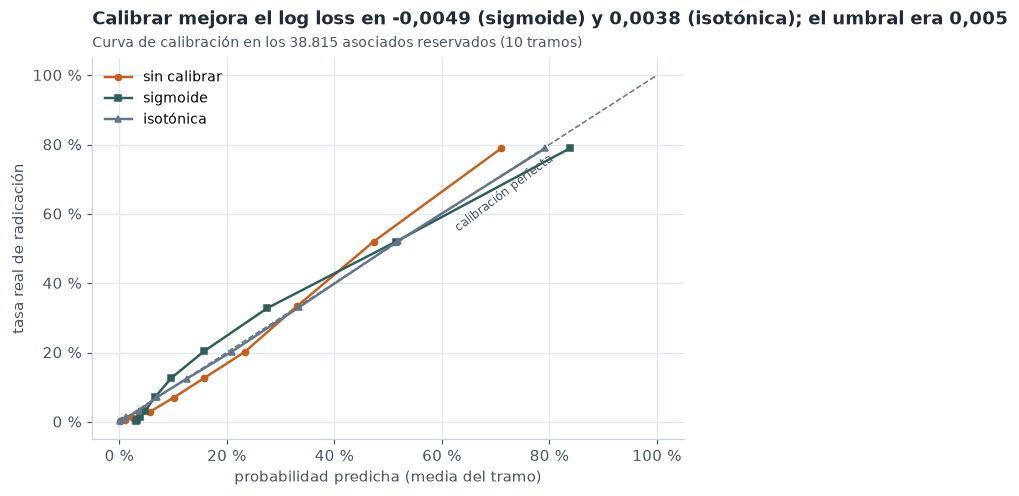

In [6]:
fig, ax = plt.subplots(figsize=(6.4, 4.6))
ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1)
ax.text(0.62, 0.55, "calibración perfecta", color=SUBTEXT, fontsize=8, rotation=37)
for (name, p), color, marker in zip(probas_cal.items(), [CHURN, STAY, NEUTRAL], ["o", "s", "^"]):
    r = reliability_table(y_res, p, n_bins=10)
    ax.plot(r["probabilidad media predicha"], r["tasa real"], color=color, marker=marker, ms=4, lw=1.6,
            label=METHOD_LABEL.get(name, name))
ax.set_xlabel("probabilidad predicha (media del tramo)"); ax.set_ylabel("tasa real de radicación")
pct_axis(ax, "x"); pct_axis(ax, "y"); ax.legend(loc="upper left")
gain = {m: base_ll - calibration.loc[m, "log loss"] for m in ["sigmoid", "isotonic"]}
titled(ax, f"Calibrar mejora el log loss en {fmt_num(gain['sigmoid'], 4)} (sigmoide) y {fmt_num(gain['isotonic'], 4)} "
           f"(isotónica); el umbral era 0,005",
       "Curva de calibración en los 38.815 asociados reservados (10 tramos)")
plt.tight_layout(); plt.show()

**Lectura y decisión.**

- **El modelo sin calibrar ya está cerca de la diagonal:** se aparta un poco en los tramos medios (predice 23 % donde radica
  el 20 %) y en el más alto (predice 71 % donde radica el 79 %).
- **Sigmoide empeora** el log loss (de 0,3243 a 0,3292) y no cambia el beneficio de forma distinguible.
- **Isotónica mejora** el log loss en 0,0038 y el beneficio neto en 0,23 millones por cada 1.000 asociados (intervalo de
  0,07 a 0,36, que no toca el cero). Pero la mejora del log loss **no llega al umbral de 0,005** que se fijó antes de mirar.
- **Decisión, aplicando la regla tal cual: no se calibra.** La calibración isotónica queda anotada como una mejora pequeña y
  posible para una versión siguiente del modelo; no se adopta ahora porque la regla se escribió antes de ver estos números
  y cambiarla después sería decidir mirando el resultado.

### 1.3 Regla de decisión (punto de operación)

Se congela la regla del notebook 01: **contactar a un asociado si probabilidad × 20 % × saldo de aportes > $30.000**. Es
la que convierte al modelo en rentable (notebook 05) y la que identifica a la clase minoritaria donde importa: donde está
el dinero en riesgo. Con ella, el umbral no es uno solo: depende del saldo de cada asociado. Como referencia operativa se
reporta también cuántos contactos haría falta para detectar al 75 % de quienes radican (la regla del notebook del equipo).

### 1.4 Las decisiones, por escrito

Se guardan en `reports/07_decisiones_congeladas.json` **con fecha y hora**, antes de abrir la prueba. Si la prueba ya se
abrió, el archivo **no se reescribe**.

In [7]:
decisions = {
    "fecha_y_hora": datetime.now().isoformat(timespec="seconds"),
    "modelo_final": "Random Forest",
    "parametros": {"n_estimators": 200, **params},
    "origen_parametros": "notebook 06: optimizados (misma PR-AUC y beneficio que los de partida en reservados, brecha 0,30 -> 0,07)",
    "calibrar": CALIBRATION or False,
    "calibracion_en_reservados": calibration.round(5).reset_index().to_dict(orient="records"),
    "metrica_principal": "beneficio neto por cada 1.000 asociados (regla de valor esperado)",
    "metricas_de_control": ["PR-AUC", "AUC", "Brier"],
    "regla_de_decision": f"contactar si p × {RETENTION_RATE} × saldo_aportes > {CONTACT_COST} (millones de COP)",
    "supuestos": {"costo_contacto": CONTACT_COST, "efectividad_retencion": RETENTION_RATE},
    "como_se_decidio": "validación cruzada (notebooks 04-06) y 25 % de asociados reservados (semilla 7); la prueba no se miró",
}
if FROZEN_PATH.exists() and MARK_PATH.exists():
    decisions = json.loads(FROZEN_PATH.read_text(encoding="utf-8"))   # la prueba ya se abrió: no se reescriben
    print("Las decisiones ya estaban congeladas el", decisions["fecha_y_hora"], "(no se modifican).")
else:
    FROZEN_PATH.write_text(json.dumps(decisions, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
    print("Decisiones congeladas:", decisions["fecha_y_hora"])
print(f"Modelo: {decisions['modelo_final']} · calibrar: {decisions['calibrar']} · regla: {decisions['regla_de_decision']}")

Decisiones congeladas: 2026-11-05T20:35:20
Modelo: Random Forest · calibrar: False · regla: contactar si p × 0.2 × saldo_aportes > 0.03 (millones de COP)


## 2. Entrenar el modelo final con **todo** el entrenamiento

Con las decisiones tomadas, el modelo final se ajusta con los 155.258 asociados de entrenamiento (reservados incluidos) y
se guarda **entero** (variables nuevas + preprocesamiento + modelo, y la calibración si se decidió) en
`models/final_pipeline.joblib`, para registrarlo en el notebook 08. Se ajusta también el **baseline** del torneo.

In [8]:
X_train, y_train = train.drop(columns=[TARGET]), train[TARGET].to_numpy()
final_params = {k: v for k, v in decisions["parametros"].items() if k != "n_estimators"}

base_final = build_pipeline(make_rf(final_params), columns).fit(X_train, y_train)   # sin calibrar (también para SHAP)
if decisions["calibrar"]:
    folds_train = make_folds(train, n_splits=3, seed=RANDOM_STATE)
    final_model = CalibratedClassifierCV(build_pipeline(make_rf(final_params), columns), method=decisions["calibrar"],
                                         cv=folds_train).fit(X_train, y_train)
else:
    final_model = base_final
baseline = DummyClassifier(strategy="most_frequent").fit(X_train, y_train)
joblib.dump(final_model, MODEL_PATH)
print("Modelo final ajustado con", fmt_num(len(train)), "asociados y guardado:", type(final_model).__name__)

Modelo final ajustado con 155.258 asociados y guardado: Pipeline


## 3. Abrir la prueba — **una sola vez**

Esta celda escribe una **marca** (`reports/prueba_abierta.txt`) y guarda las probabilidades de la prueba. Si el notebook
se vuelve a ejecutar, **no vuelve a calcular nada con la prueba**: reutiliza esas probabilidades y lo dice.

In [9]:
test = joblib.load(TEST_PATH)
X_test, y_test = test.drop(columns=[TARGET]), test[TARGET].to_numpy()
value_test = test["saldo_aportes"].to_numpy()

if MARK_PATH.exists() and CACHE_PATH.exists():
    proba_test, proba_base = joblib.load(CACHE_PATH)
    print("La prueba ya se abrió:", MARK_PATH.read_text(encoding="utf-8").strip())
    print("Se reutilizan sus probabilidades; no se vuelve a evaluar el modelo con la prueba.")
elif MARK_PATH.exists():
    raise RuntimeError("La prueba ya se abrió y no hay probabilidades guardadas: declararlo en el reporte antes de reabrirla.")
else:
    proba_test = final_model.predict_proba(X_test)[:, 1]
    proba_base = baseline.predict_proba(X_test)[:, 1]
    joblib.dump((proba_test, proba_base), CACHE_PATH)
    MARK_PATH.write_text(f"Prueba abierta el {datetime.now().isoformat(timespec='seconds')} · modelo Random Forest · "
                         f"{len(test):,} asociados. Una sola vez.\n".replace(",", "."), encoding="utf-8")
    print("Prueba abierta ahora; marca escrita en", MARK_PATH.name)

m_test, m_base = fold_metrics(y_test, proba_test, value_test), fold_metrics(y_test, proba_base, value_test)
mass = campaign_value(y_test, np.ones(len(y_test)), value_test, CONTACT_COST, RETENTION_RATE)
board = pd.DataFrame({"modelo final": m_test, "baseline (clase mayoritaria)": m_base}).loc[
    ["PR-AUC", "AUC", "beneficio neto (por 1.000)", "contactos (por 1.000)", "saldo cubierto", "Brier", "log loss",
     "exactitud balanceada", "recall", "precisión", "F1", "recall clase 0", "F1 macro"]]
board.loc["beneficio neto (por 1.000)", "contactar a todos"] = mass["beneficio_neto"] / len(y_test) * 1000
display(table(board, decimals=4))
print(f"Prueba: {fmt_num(len(test))} asociados · {fmt_num(y_test.sum())} radicaron ({fmt_pct(y_test.mean())})")

Prueba abierta ahora; marca escrita en prueba_abierta.txt


,modelo final,baseline (clase mayoritaria),contactar a todos
PR-AUC,"0,7004","0,2091",nan
AUC,"0,8958","0,5000",nan
beneficio neto (por 1.000),"33,6011","0,0000","18,7888"
contactos (por 1.000),"410,4083","0,0000",nan
saldo cubierto,"0,9411","0,0000",nan
Brier,"0,1014","0,2091",nan
log loss,"0,3207","2,8895",nan
exactitud balanceada,"0,7224","0,5000",nan
recall,"0,4879","0,0000",nan
precisión,"0,7492","0,0000",nan


Prueba: 38.815 asociados · 8.118 radicaron (20,9 %)


## 4. Intervalos y comparación con las referencias — remuestreando asociados

Una cifra sin intervalo no dice cuánto confiar en ella. Se calcula el intervalo del 95 % (500 remuestreos de asociados)
de las métricas principales y de las diferencias con las dos referencias: el **baseline** del torneo y **contactar a
todos**, que es la línea base de negocio del notebook 01.

In [10]:
groups_test = test[ID_COL].to_numpy()

def pr_auc_t(rows, p): return average_precision_score(y_test[rows], p[rows])
def auc_t(rows, p): return roc_auc_score(y_test[rows], p[rows])
def brier_t(rows, p): return brier_score_loss(y_test[rows], p[rows])
def benefit_t(rows, p):
    contact = contact_by_expected_value(p[rows], value_test[rows], CONTACT_COST, RETENTION_RATE)
    return campaign_value(y_test[rows], contact, value_test[rows], CONTACT_COST, RETENTION_RATE)["beneficio_neto"] / len(rows) * 1000
def benefit_vs_mass(rows, p):
    everyone = campaign_value(y_test[rows], np.ones(len(rows)), value_test[rows], CONTACT_COST, RETENTION_RATE)
    return benefit_t(rows, p) - everyone["beneficio_neto"] / len(rows) * 1000

ci_rows = []
for label, fn in [("PR-AUC", pr_auc_t), ("AUC", auc_t), ("Brier", brier_t), ("beneficio neto (por 1.000)", benefit_t)]:
    ci_rows.append(("modelo final", label, *bootstrap_metric(fn, proba_test, groups_test)))
ci_rows.append(("modelo − baseline", "PR-AUC", *bootstrap_difference(pr_auc_t, proba_test, proba_base, groups_test)))
ci_rows.append(("modelo − contactar a todos", "beneficio neto (por 1.000)", *bootstrap_metric(benefit_vs_mass, proba_test, groups_test)))
intervals = pd.DataFrame(ci_rows, columns=["qué", "métrica", "valor", "IC 95 % inferior", "IC 95 % superior"]).set_index(["qué", "métrica"])
display(table(intervals, decimals=4))
beats = (intervals.loc[("modelo − baseline", "PR-AUC"), "IC 95 % inferior"] > 0 and
         intervals.loc[("modelo − contactar a todos", "beneficio neto (por 1.000)"), "IC 95 % inferior"] > 0)
print("¿Supera al baseline y a contactar a todos con confianza (intervalos sin cruzar el cero)?", "SÍ" if beats else "NO")

¿Supera al baseline y a contactar a todos con confianza (intervalos sin cruzar el cero)? SÍ


### ¿Se comporta como se esperaba? Prueba frente a validación

Si la prueba da cifras parecidas a las de la validación, el modelo **generaliza** y las decisiones tomadas sin mirarla
eran confiables. Se compara con la validación cruzada del 06 y con los asociados reservados; y se mide la brecha de
sobreajuste en la prueba.

In [11]:
check6 = pd.read_csv(REPORTS_DIR / "06_comprobacion.csv", index_col=0).loc["optimizado"]
cv6 = pd.read_csv(REPORTS_DIR / "06_optimizacion_tabla.csv", index_col=0).loc[stage6["mejor_ensayo"]]
fit_sample = np.random.default_rng(RANDOM_STATE).choice(len(train), TRAIN_SAMPLE, replace=False)
p_fit = final_model.predict_proba(X_train.iloc[fit_sample])[:, 1]
pr_fit = average_precision_score(y_train[fit_sample], p_fit)
generalization = pd.DataFrame({
    "validación cruzada (06)": [cv6["PR-AUC"], cv6["AUC"], cv6["beneficio neto (por 1.000)"]],
    "reservados (06)": [check6["PR-AUC (reservados)"], check6["AUC (reservados)"], check6["beneficio neto (por 1.000)"]],
    "prueba": [m_test["PR-AUC"], m_test["AUC"], m_test["beneficio neto (por 1.000)"]],
}, index=["PR-AUC", "AUC", "beneficio neto (por 1.000)"])
display(table(generalization, decimals=4))
print(f"Brecha de sobreajuste en la prueba: PR-AUC en lo que vio {fmt_num(pr_fit, 4)} − en la prueba "
      f"{fmt_num(m_test['PR-AUC'], 4)} = {fmt_num(pr_fit - m_test['PR-AUC'], 4)} (tope fijado en el 06: 0,10)")

,validación cruzada (06),reservados (06),prueba
PR-AUC,"0,6966","0,6971","0,7004"
AUC,"0,8931","0,8932","0,8958"
beneficio neto (por 1.000),"33,5148","33,4374","33,6011"


Brecha de sobreajuste en la prueba: PR-AUC en lo que vio 0,7670 − en la prueba 0,7004 = 0,0666 (tope fijado en el 06: 0,10)


**Lectura de la prueba.**

- **El modelo generaliza.** En la prueba logra PR-AUC 0,7004 (intervalo 0,690 a 0,711), AUC 0,8958 y un beneficio neto de
  33,60 millones por cada 1.000 asociados. Son prácticamente las mismas cifras de la validación cruzada (0,6966) y de los
  reservados del 06 (0,6971): las decisiones tomadas sin mirar la prueba eran confiables.
- **El sobreajuste se mantuvo controlado:** la brecha de PR-AUC entre lo que el modelo vio y la prueba es de 0,067, por
  debajo del tope de 0,10 que se fijó en el 06 (en los reservados había sido 0,074).
- **Supera a las dos referencias con confianza.** Frente al baseline, 0,49 más de PR-AUC (intervalo 0,48 a 0,50). Frente a
  contactar a todos, **14,81 millones más por cada 1.000 asociados** (intervalo 14,61 a 15,00). Ningún intervalo toca el
  cero.
- **En el umbral 0,5** detecta al 48,8 % de quienes radican con precisión de 74,9 %. Ese no es el punto de operación: la
  regla de valor esperado (sección 5) es la que decide.

## 5. Errores y carga de trabajo — lo que la métrica no ve

### 5.1 La campaña que propone el modelo

In [12]:
contact = contact_by_expected_value(proba_test, value_test, CONTACT_COST, RETENTION_RATE)
campaign = campaign_value(y_test, contact, value_test, CONTACT_COST, RETENTION_RATE)
effort75 = contacts_for_recall(y_test, proba_test, 0.75)
found75 = effort75["contactos"] - effort75["falsas alarmas"]
summary = pd.DataFrame({
    "regla de valor esperado": [fmt_num(campaign["contactados"]), fmt_num(campaign["VP"]), fmt_num(campaign["FP"]),
                                fmt_num(campaign["FN"]), fmt_pct(campaign["VP"] / y_test.sum()),
                                fmt_pct(campaign["VP"] / max(campaign["contactados"], 1)), fmt_pct(campaign["saldo_cubierto"]),
                                fmt_num(campaign["beneficio_neto"], 1)],
    "referencia: detectar al 75 %": [fmt_num(effort75["contactos"]), fmt_num(found75), fmt_num(effort75["falsas alarmas"]),
                                     fmt_num(y_test.sum() - found75), fmt_pct(effort75["recall alcanzado"]),
                                     fmt_pct(effort75["precisión"]), "—", "—"],
}, index=["asociados contactados", "contactados que radicaban (VP)", "contactados que no radicaban (FP)",
          "radicaban y no se contactaron (FN)", "recall", "precisión", "saldo en riesgo cubierto",
          "beneficio neto (millones de COP)"])
display(summary)
exits = test["exit_without_request"] == 1
print(f"De los {fmt_num(exits.sum())} asociados de la prueba que la cooperativa retiró de forma unilateral, la regla contacta a "
      f"{fmt_pct(contact[exits].mean())} (frente a {fmt_pct(contact[~exits & (y_test == 0)].mean())} de los activos que no radicaron).")

,regla de valor esperado,referencia: detectar al 75 %
asociados contactados,15.930,10.523
contactados que radicaban (VP),6.142,6.089
contactados que no radicaban (FP),9.788,4.434
radicaban y no se contactaron (FN),1.976,2.029
recall,"75,7 %","75,0 %"
precisión,"38,6 %","57,9 %"
saldo en riesgo cubierto,"94,1 %",—
beneficio neto (millones de COP),"1.304,2",—


De los 4.738 asociados de la prueba que la cooperativa retiró de forma unilateral, la regla contacta a 26,1 % (frente a 32,9 % de los activos que no radicaron).


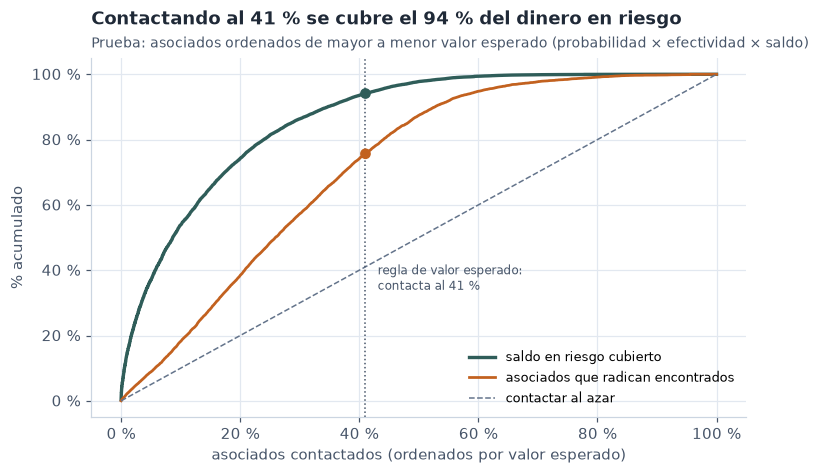

In [13]:
expected_value = proba_test * RETENTION_RATE * value_test
order = np.argsort(-expected_value, kind="stable")
share_people = np.arange(1, len(order) + 1) / len(order)
share_money = np.cumsum((value_test * y_test)[order]) / (value_test * y_test).sum()
share_filers = np.cumsum(y_test[order]) / y_test.sum()
k = contact.sum()

fig, ax = plt.subplots(figsize=(7.6, 4.4))
ax.plot(share_people, share_money, color=STAY, lw=2.2, label="saldo en riesgo cubierto")
ax.plot(share_people, share_filers, color=CHURN, lw=1.8, label="asociados que radican encontrados")
ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1, label="contactar al azar")
ax.axvline(k / len(order), color=SUBTEXT, ls=":", lw=1)
ax.scatter([k / len(order)] * 2, [share_money[k - 1], share_filers[k - 1]], color=[STAY, CHURN], zorder=3)
ax.annotate(f"regla de valor esperado:\ncontacta al {fmt_pct(k / len(order), 0)}", (k / len(order), 0.34),
            xytext=(8, 0), textcoords="offset points", fontsize=8, color=SUBTEXT)
pct_axis(ax, "x"); pct_axis(ax, "y")
ax.set_xlabel("asociados contactados (ordenados por valor esperado)"); ax.set_ylabel("% acumulado")
ax.legend(loc="lower right", fontsize=8.5)
titled(ax, f"Contactando al {fmt_pct(k / len(order), 0)} se cubre el {fmt_pct(share_money[k - 1], 0)} del dinero en riesgo",
       "Prueba: asociados ordenados de mayor a menor valor esperado (probabilidad × efectividad × saldo)")
plt.tight_layout(); plt.show()

**Lectura de la campaña.**

- **Con la regla de valor esperado, la campaña contactaría a 15.930 de los 38.815 asociados de la prueba (41 %)** y
  encontraría al 75,7 % de quienes radican (6.142 de 8.118), cubriendo el **94,1 % del saldo de aportes en riesgo**. Con los
  supuestos de costo y efectividad, dejaría 1.304 millones de beneficio neto en esta población.
- **Prioriza el dinero, no solo a las personas:** para encontrar al 75 % de quienes radican bastarían 10.523 contactos
  (precisión 57,9 %), pero la regla contacta a unos 5.400 más porque son asociados con saldos altos: aun con baja
  probabilidad, el valor esperado de llamarlos supera los 30.000 pesos. Por eso cubre casi todo el dinero con el 41 % de
  los contactos.
- **El costo operativo:** 9.788 contactos (61 % de los contactos) son a asociados que no iban a radicar. Es el precio
  aceptado desde el notebook 01 (cada uno cuesta el contacto), y **mercadeo debe confirmar que tiene capacidad** para
  llamar a cerca del 41 % de los asociados por campaña.
- **Retiros unilaterales:** la regla contacta al 26,1 % de quienes la cooperativa terminó retirando por su cuenta, frente al
  32,9 % de los activos que no radicaron. Son contactos que no evitan nada, pero el modelo ya los prioriza menos.

### 5.2 ¿Las probabilidades de la prueba son creíbles?

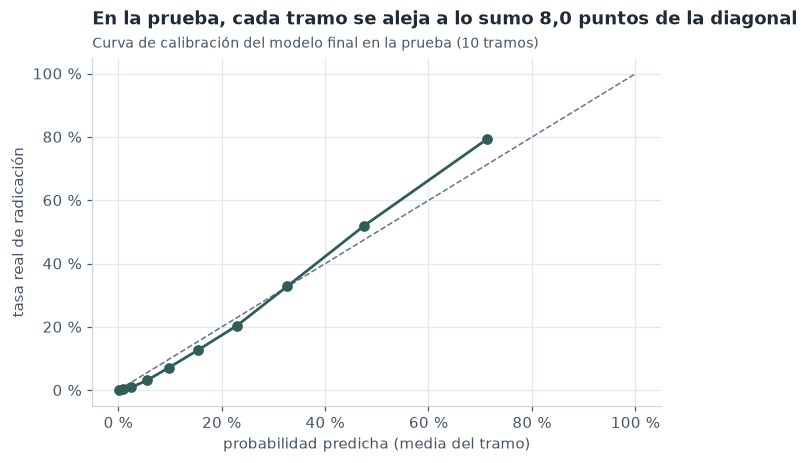

,probabilidad media predicha,tasa real
0,"0,2 %","0,2 %"
1,"1,0 %","0,3 %"
2,"2,5 %","1,0 %"
3,"5,5 %","3,1 %"
4,"9,8 %","7,2 %"
5,"15,4 %","12,7 %"
6,"23,0 %","20,4 %"
7,"32,7 %","32,9 %"
8,"47,6 %","52,0 %"
9,"71,3 %","79,4 %"


In [14]:
rel = reliability_table(y_test, proba_test, n_bins=10)
fig, ax = plt.subplots(figsize=(6.2, 4.3))
ax.plot([0, 1], [0, 1], color=NEUTRAL, ls="--", lw=1)
ax.plot(rel["probabilidad media predicha"], rel["tasa real"], color=STAY, marker="o", lw=1.8)
pct_axis(ax, "x"); pct_axis(ax, "y")
ax.set_xlabel("probabilidad predicha (media del tramo)"); ax.set_ylabel("tasa real de radicación")
max_gap = (rel["tasa real"] - rel["probabilidad media predicha"]).abs().max()
titled(ax, f"En la prueba, cada tramo se aleja a lo sumo {fmt_num(max_gap * 100, 1)} puntos de la diagonal",
       "Curva de calibración del modelo final en la prueba (10 tramos)")
plt.tight_layout(); plt.show()
display(table(rel, pct_cols=["probabilidad media predicha", "tasa real"]))

**Lectura.** Las probabilidades son creíbles en el rango medio (en el tramo de 33 % radica el 33 %). En los extremos hay un
sesgo conocido de los bosques: en el tramo de mayor riesgo **subestima** (predice 71 % y radica el 79 %, la mayor
desviación) y en los tramos bajos **sobreestima** un poco (predice 5,5 % y radica el 3,1 %). Es el mismo patrón que se vio en
los reservados antes de abrir la prueba. Para la regla de valor esperado no es grave: los asociados de mayor riesgo se
contactan igual, y en los de bajo riesgo el error es de pocos puntos. Por eso la calibración isotónica (sección 1.2) queda
como mejora candidata para la siguiente versión.

### 5.3 Errores por segmento: ¿el modelo funciona igual para todos?

Segmentos con sentido para el negocio y para la equidad: edad, sexo, zona, educación, ocupación y la ventana de riesgo
de antigüedad. La señal de alarma de la guía: un segmento donde el **% contactado** y la **tasa real** se separan mucho,
o donde el **recall** cae frente al resto.

In [15]:
seg = pd.DataFrame({"real": y_test, "contactar": contact, "proba": proba_test})
seg["edad"] = pd.cut(test["edad"].to_numpy(), [13, 25, 35, 50, 65, 100], labels=["14–25", "26–35", "36–50", "51–65", "66–100"])
seg["sexo"] = np.where(test["femenino"] == 1, "femenino", "masculino")
seg["zona"] = np.where(test["zona_med"] == 1, "Medellín", "otras zonas")
seg["educación"] = np.where(test["ed_superior"] == 1, "superior", "otra")
seg["ocupación"] = np.where(test["asalariado"] == 1, "asalariado", "otra")
seg["antigüedad"] = pd.cut(test["antig_meses"].to_numpy(), [-1, 6, 24, 60, 108],
                           labels=["0–6 meses", "7–24 meses", "25–60 meses", "61 meses o más"])
segments = pd.concat([segment_table(seg, s) for s in ["edad", "sexo", "zona", "educación", "ocupación", "antigüedad"]])
overall_recall = campaign["VP"] / y_test.sum()
segments["recall frente al total (puntos)"] = (segments["recall"] - overall_recall) * 100
display(table(segments, decimals=3, pct_cols=["tasa real", "% contactado", "probabilidad media", "recall", "precisión"],
              col_decimals={"recall frente al total (puntos)": 1}))

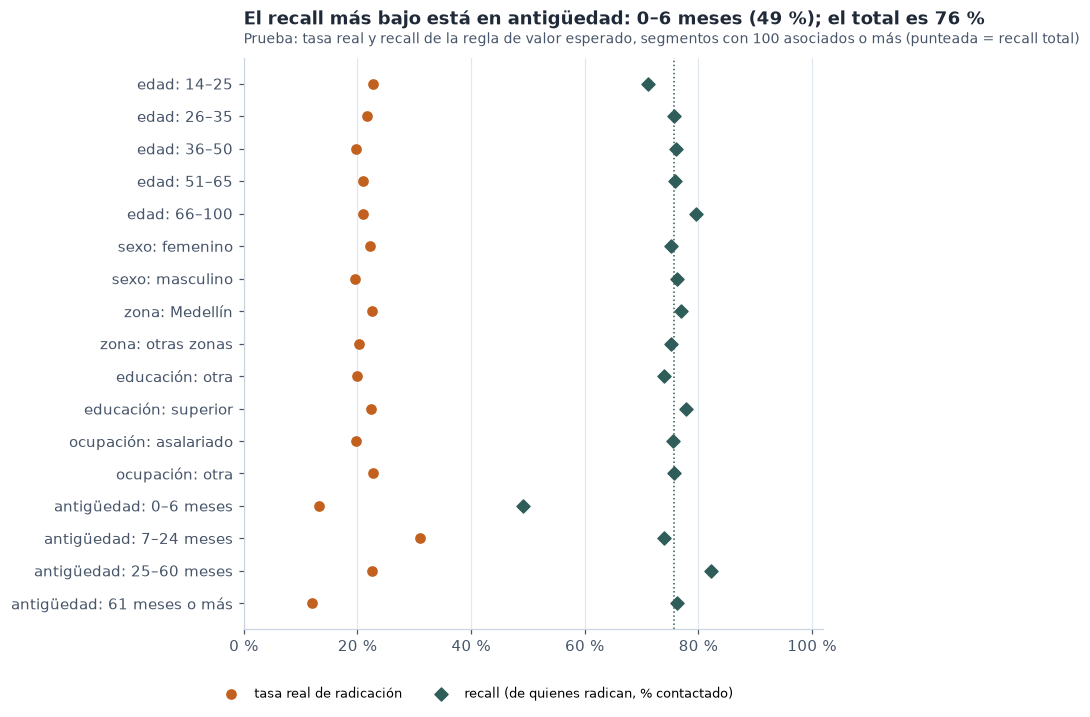

In [16]:
plot = segments[segments["asociados"] >= 100].reset_index()   # los segmentos muy pequeños solo van en la tabla
plot["etiqueta"] = plot["segmento"] + ": " + plot["valor"]
fig, ax = plt.subplots(figsize=(8.6, 6.6))
y_pos = np.arange(len(plot))[::-1]
ax.scatter(plot["tasa real"], y_pos, color=CHURN, s=36, label="tasa real de radicación", zorder=3)
ax.scatter(plot["recall"], y_pos, color=STAY, s=36, marker="D", label="recall (de quienes radican, % contactado)", zorder=3)
ax.axvline(overall_recall, color=STAY, ls=":", lw=1)
ax.set_yticks(y_pos); ax.set_yticklabels(plot["etiqueta"]); pct_axis(ax, "x"); ax.set_xlim(0, 1.02)
ax.grid(axis="y", visible=False)
ax.legend(loc="upper center", bbox_to_anchor=(0.4, -0.08), ncol=2, fontsize=8.5)
worst = plot.loc[plot["recall"].idxmin()]
titled(ax, f"El recall más bajo está en {worst['etiqueta']} ({fmt_pct(worst['recall'], 0)}); el total es {fmt_pct(overall_recall, 0)}",
       "Prueba: tasa real y recall de la regla de valor esperado, segmentos con 100 asociados o más (punteada = recall total)")
plt.tight_layout(); plt.show()

**Lectura por segmento.**

- **Equidad: el modelo funciona parecido para todos los grupos sociodemográficos.** El recall va de 74,0 % a 79,5 % entre
  sexo, zona, educación, ocupación y edad. El grupo con el recall más bajo es el más joven (14–25 años: 71,1 %, 4,6 puntos por
  debajo del total). Es una diferencia a vigilar, no una alarma.
- **La alarma está en la antigüedad: los asociados nuevos (0–6 meses).** El modelo encuentra solo al 49,2 % de quienes
  radican entre ellos (26 puntos menos que el total) y contacta al 14 %. Tiene sentido: tienen pocos meses de historia
  (visitas, capitalizaciones) y poco saldo, así que la regla les asigna poco valor esperado. Para ellos el modelo **no es
  la herramienta adecuada**: conviene una estrategia propia de bienvenida y fidelización temprana.
- **En los asociados antiguos (61 meses o más) la regla contacta al 40,7 % aunque solo radica el 12,0 %** (precisión 22,5 %):
  tienen saldos altos y el valor esperado justifica la llamada. Es la regla de negocio funcionando como se diseñó, no un
  error del modelo.
- La tabla incluye 5 asociados sin edad registrada, demasiado pocos para leer su recall.

## 6. ¿Por qué decide así el modelo? — SHAP, con sus límites

SHAP reparte cada predicción entre las variables: cuánto empuja cada una la probabilidad de radicar hacia arriba o hacia
abajo. Se calcula sobre una **muestra de 600 asociados del entrenamiento** (la prueba no interviene) y sobre el modelo
**sin calibrar** (la calibración solo reajusta la escala de las probabilidades).

> **Los límites que hay que escribir siempre:** SHAP explica **al modelo**, no **al mundo**. Que una variable pese mucho
> dice que el modelo se apoya en ella, no que *cause* el retiro. Las variables correlacionadas se reparten el crédito
> (notebook 02, matriz de correlación). Y una explicación no dice si el modelo acertó.

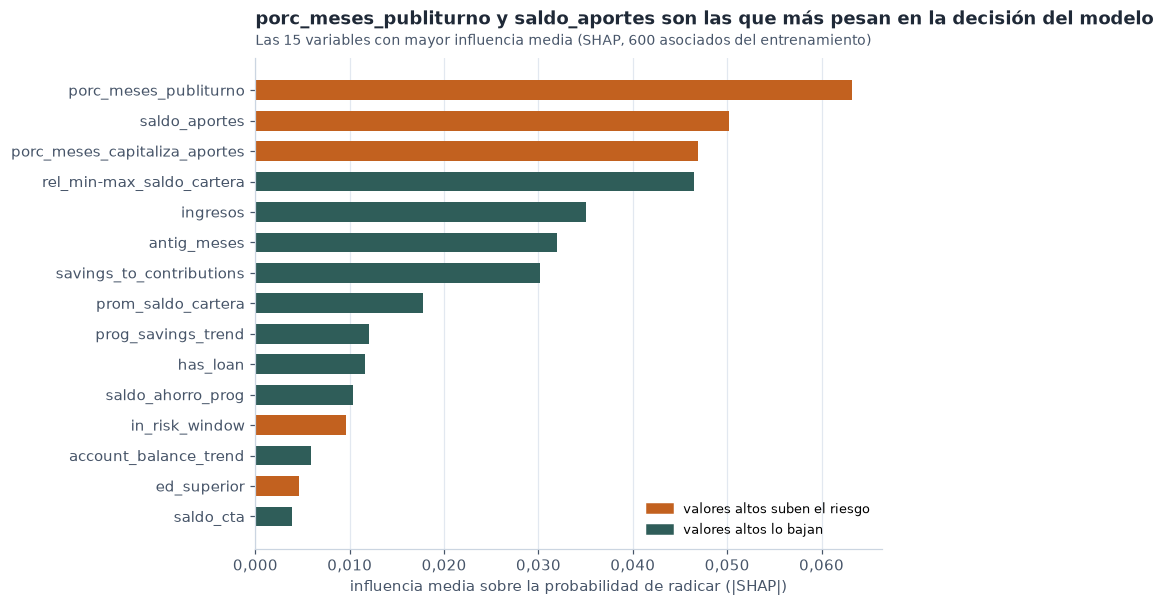

,influencia media |SHAP|,dirección,% del total
porc_meses_publiturno,"0,0632","0,73","15,5 %"
saldo_aportes,"0,0502","0,21","12,3 %"
porc_meses_capitaliza_aportes,"0,0469","0,82","11,5 %"
rel_min-max_saldo_cartera,"0,0464","-0,89","11,4 %"
ingresos,"0,0351","-0,39","8,6 %"
antig_meses,"0,0320","-0,77","7,9 %"
savings_to_contributions,"0,0301","-0,66","7,4 %"
prom_saldo_cartera,"0,0177","-0,84","4,4 %"
prog_savings_trend,"0,0120","-0,53","3,0 %"
has_loan,"0,0116","-0,82","2,9 %"


In [17]:
import shap

sample = train.sample(600, random_state=RANDOM_STATE)
prep, forest = base_final.named_steps["prep"], base_final.named_steps["model"]
Xt = prep.transform(sample.drop(columns=[TARGET]))
names = list(prep.named_steps["preprocess"].get_feature_names_out())
raw_values = shap.TreeExplainer(forest).shap_values(Xt, check_additivity=False)
values = raw_values[1] if isinstance(raw_values, list) else (raw_values[:, :, 1] if raw_values.ndim == 3 else raw_values)
importance = shap_importance(values, Xt, names)
importance["% del total"] = importance["influencia media |SHAP|"] / importance["influencia media |SHAP|"].sum()

top = importance.head(15)[::-1]
fig, ax = plt.subplots(figsize=(8.2, 5.6))
ax.barh(top.index, top["influencia media |SHAP|"], color=[CHURN if d > 0 else STAY for d in top["dirección"]], height=0.65)
ax.set_xlabel("influencia media sobre la probabilidad de radicar (|SHAP|)")
ax.grid(axis="y", visible=False)
from matplotlib.patches import Patch
ax.legend(handles=[Patch(color=CHURN, label="valores altos suben el riesgo"), Patch(color=STAY, label="valores altos lo bajan")],
          loc="lower right", fontsize=8.5)
decimal_axis(ax, "x", 3)
titled(ax, f"{importance.index[0]} y {importance.index[1]} son las que más pesan en la decisión del modelo",
       "Las 15 variables con mayor influencia media (SHAP, 600 asociados del entrenamiento)")
plt.tight_layout(); plt.show()
display(table(importance.head(15), decimals=4, pct_cols=["% del total"], col_decimals={"dirección": 2}))

In [18]:
sensitive = ["edad", "femenino", "zona_med", "ed_superior", "asalariado"]
suspects = [c for c in SUSPECT_COLUMNS if c in importance.index] + \
           [c for c in ["account_balance_trend", "prog_savings_trend"] if c in importance.index]
groups_imp = pd.DataFrame({
    "variables": [", ".join(sensitive), ", ".join(suspects)],
    "% de la influencia total": [importance.loc[[c for c in sensitive if c in importance.index], "% del total"].sum(),
                                 importance.loc[suspects, "% del total"].sum()],
}, index=["sociodemográficas (uso sensible)", "sospechas de fuga (notebooks 02 y 04)"])
display(table(groups_imp, pct_cols=["% de la influencia total"]))
display(table(importance.loc[[c for c in sensitive if c in importance.index]], decimals=4, pct_cols=["% del total"],
              col_decimals={"dirección": 2}))

,variables,% de la influencia total
sociodemográficas (uso sensible),"edad, femenino, zona_med, ed_superior, asalariado","2,9 %"
sospechas de fuga (notebooks 02 y 04),"porc_meses_publiturno, rel_min-max_saldo_cartera, ingresos, account_balance_trend, prog_savings_trend","40,0 %"


,influencia media |SHAP|,dirección,% del total
edad,"0,0034","-0,73","0,8 %"
femenino,"0,0007","0,79","0,2 %"
zona_med,"0,0012","0,85","0,3 %"
ed_superior,"0,0046","0,89","1,1 %"
asalariado,"0,0018","-0,09","0,4 %"


**Lectura (con sus límites).**

- **Lo que más pesa en el modelo es el comportamiento:** frecuencia de visitas a sucursal (15,5 % de la influencia) y de
  capitalización de aportes (11,5 %), que **suben** el riesgo, y la cartera (razón mínimo/máximo, 11,4 %; saldo promedio),
  la antigüedad y el ahorro fuera de los aportes, que lo **bajan**. El saldo de aportes pesa mucho (12,3 %) pero su efecto no
  es de una sola dirección: con aportes casi nulos nadie radica (no hay nada que retirar) y con aportes moderados el riesgo
  es mayor (notebook 02).
- **Lectura de negocio (asociación, no causa):** el perfil que radica usa la cooperativa de forma transaccional y ve los
  aportes como un ahorro disponible; el que permanece tiene crédito y otros productos. Coincide con la conclusión del
  notebook del equipo: *"el crédito ata, los aportes sueltos no"*. Pero eso **no autoriza a concluir que ofrecer crédito
  retiene**: solo un piloto con grupo de control puede decirlo.
- **Atributos sensibles:** edad, sexo, zona, educación y ocupación suman solo el **2,9 %** de la influencia total. El modelo
  no se apoya en ellos, y el error por segmento (sección 5.3) lo confirma. Igual deben declararse en la ficha del modelo y
  revisarse con el área jurídica antes de producción.
- **La advertencia más importante:** las variables sospechosas de fuga (visitas, cartera mínima en cero, ingreso y las dos
  tendencias de saldo) suman el **40 %** de la influencia. El equipo confirmó que no incluyen el mes de radicación, pero si
  alguna reflejara el trámite de retiro, parte del desempeño sería optimista. El notebook 05 midió el peor caso sin ellas:
  el modelo seguía superando con holgura a contactar a todos.

## 7. Guardar los resultados de la etapa

In [19]:
results = {
    "modelo_final": "Random Forest", "decisiones_congeladas": decisions["fecha_y_hora"],
    "prueba": {"asociados": int(len(test)), "radicaron": int(y_test.sum()), "marca": MARK_PATH.read_text(encoding="utf-8").strip()},
    "metricas_modelo": m_test, "metricas_baseline": m_base,
    "beneficio_contactar_a_todos_por_1000": mass["beneficio_neto"] / len(y_test) * 1000,
    "intervalos": intervals.reset_index().to_dict(orient="records"),
    "supera_referencias_con_confianza": bool(beats),
    "campaña": {k: (float(v) if isinstance(v, (int, float, np.floating, np.integer)) else v) for k, v in campaign.items()},
    "detectar_75": effort75,
}
(OUT_DIR / "07_resultados.json").write_text(json.dumps(results, indent=2, ensure_ascii=False, default=float), encoding="utf-8")
segments.round(4).to_csv(OUT_DIR / "07_errores_por_segmento.csv", encoding="utf-8")
importance.round(5).to_csv(OUT_DIR / "07_importancia_shap.csv", encoding="utf-8")
print("Guardado: 07_resultados.json, 07_errores_por_segmento.csv, 07_importancia_shap.csv,",
      "07_decisiones_congeladas.json, prueba_abierta.txt y el modelo final")

Guardado: 07_resultados.json, 07_errores_por_segmento.csv, 07_importancia_shap.csv, 07_decisiones_congeladas.json, prueba_abierta.txt y el modelo final


## 8. Conclusiones

1. **El modelo sirve para la decisión del caso.** En asociados que nunca vio, ordena bien el riesgo (PR-AUC 0,70; AUC 0,90),
   generaliza como en la validación y, con la regla de valor esperado, deja **14,8 millones más por cada 1.000 asociados que
   contactar a todos**, cubriendo el 94 % del dinero en riesgo con el 41 % de los contactos.
2. **Los objetivos del equipo se cumplieron:** sobreajuste controlado (brecha 0,067 en la prueba) y la clase minoritaria
   identificada donde importa: tres de cada cuatro asociados que radican, y casi todo el saldo en riesgo.
3. **Condiciones para usarlo:**
   - Validar los supuestos de **costo del contacto y efectividad de la retención** con un **piloto con grupo de control**:
     las cifras en pesos dependen de ellos.
   - Confirmar que mercadeo tiene **capacidad para contactar a cerca del 41 %** de los asociados por campaña (o ajustar la
     regla a la capacidad real).
   - Aclarar la ventana de cálculo de las variables sospechosas, que pesan el 40 % del modelo.
   - **Complementar con otra estrategia para los asociados nuevos (0–6 meses)**, donde el modelo encuentra a la mitad.
   - Recalibrar y revisar el modelo cada seis meses (nuevas cohortes, cambios de productos).
4. **Qué NO debe hacerse con él:** negar productos o servicios a ningún asociado; leer sus variables como causas del
   retiro; usarlo para decidir sobre grupos sociodemográficos; ni volver a abrir esta prueba para "mejorarlo": cualquier
   cambio se valida con datos nuevos.

**Constancia:** decisiones congeladas el 2026-11-05 a las 20:35:20 (`reports/07_decisiones_congeladas.json`); prueba abierta
una sola vez el 2026-11-05 a las 20:36:06 (`reports/prueba_abierta.txt`). No se cambió nada del modelo después de verla.

## Entregable de esta etapa

- [x] Decisiones (modelo, parámetros, calibración, regla) **congeladas con fecha y hora** antes de abrir la prueba.
- [x] Calibración decidida con asociados reservados, no con la prueba.
- [x] Modelo final entrenado con todo el entrenamiento y guardado entero (`models/final_pipeline.joblib`).
- [x] Prueba abierta **una sola vez** (marca en `reports/prueba_abierta.txt`).
- [x] Intervalos remuestreando asociados y comparación con el baseline y con contactar a todos.
- [x] Errores por segmento, carga de trabajo e interpretación con SHAP y sus límites.
- [x] `reports/07_validacion.md` redactado con estas cifras.

**Siguiente:** `08_registro_modelo.ipynb`: registrar el modelo con versión y alias.